In [1]:
!pip install -q pandas numpy matplotlib seaborn scikit-learn

In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import random

from datetime import datetime, timedelta

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)

sns.set_theme(style="whitegrid")

random.seed(42)
np.random.seed(42)

print("Jan-Samadhan project initialized successfully")

Jan-Samadhan project initialized successfully


In [6]:
# Phase 1 – Data Exploration and Visualization
# Create a sample dataset
departments = {
    "Revenue": [
        "My land record has not been updated",
        "My mutation application is pending",
        "My caste certificate has not been issued",
        "My income certificate application is delayed"
    ],

    "Rural Development": [
        "My PMAY housing application is pending",
        "MGNREGA wages have not been credited",
        "Our village road is damaged",
        "My pension payment is pending"
    ],

    "Health": [
        "The government hospital did not provide treatment",
        "Essential medicines are unavailable",
        "My health insurance claim is pending",
        "The primary health centre is not functioning"
    ],

    "Education": [
        "My scholarship application is pending",
        "The school building requires repair",
        "There is no regular teacher",
        "Students are not receiving mid-day meals"
    ],

    "Electricity": [
        "Our village has frequent power cuts",
        "The electricity transformer is damaged",
        "My electricity bill is incorrect",
        "My new electricity connection is pending"
    ],

    "Water Supply": [
        "Safe drinking water is unavailable",
        "The public water pipeline is leaking",
        "The community hand pump is not working",
        "Drinking water quality is poor"
    ]
}

records = []

for i in range(500):

    department = random.choice(list(departments.keys()))

    complaint = random.choice(departments[department])

    extra_text = random.choice([
        "Please resolve this issue immediately.",
        "I have visited the office several times.",
        "My family is facing serious difficulties.",
        "Kindly take necessary action."
    ])

    received_date = datetime(2025, 1, 1) + timedelta(
        days=random.randint(0, 365)
    )

    records.append({

        "Complaint_ID": f"JS{i+1001}",

        "State": random.choice([
            "Odisha",
            "Chhattisgarh",
            "Jharkhand",
            "Bihar",
            "West Bengal"
        ]),

        "Date": received_date,

        "Department": department,

        "Status": random.choice([
            "Pending",
            "In Progress",
            "Resolved"
        ]),

        "Description": complaint + " " + extra_text

    })

df = pd.DataFrame(records)

df.to_csv("jan_samadhan_dataset.csv", index=False)

print("Dataset created successfully")
print("Total complaints:", len(df))

df.head()

Dataset created successfully
Total complaints: 500


,Complaint_ID,State,Date,Department,Status,Description
0,JS1001,Bihar,2025-10-22,Education,In Progress,Students are not receiving mid-day meals I hav...
1,JS1002,Chhattisgarh,2025-10-12,Rural Development,In Progress,My pension payment is pending I have visited t...
2,JS1003,Bihar,2025-06-11,Health,Resolved,Essential medicines are unavailable I have vis...
3,JS1004,Chhattisgarh,2025-09-06,Revenue,Pending,My caste certificate has not been issued Pleas...
4,JS1005,Bihar,2025-12-17,Education,In Progress,Students are not receiving mid-day meals Kindl...


In [4]:
# Identify structured and unstructured data
print("Dataset information")
df.info()

print("\nFirst five records")
display(df.head())

print("\nMissing values")
print(df.isnull().sum())

Dataset information
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   Complaint_ID  500 non-null    object        
 1   State         500 non-null    object        
 2   Date          500 non-null    datetime64[ns]
 3   Department    500 non-null    object        
 4   Status        500 non-null    object        
 5   Description   500 non-null    object        
dtypes: datetime64[ns](1), object(5)
memory usage: 23.6+ KB

First five records


,Complaint_ID,State,Date,Department,Status,Description
0,JS1001,Chhattisgarh,2025-05-21,Water Supply,Pending,Safe drinking water is unavailable Please reso...
1,JS1002,Bihar,2025-10-30,Rural Development,Pending,My PMAY housing application is pending Please ...
2,JS1003,West Bengal,2025-04-30,Revenue,Resolved,My land record has not been updated I have vis...
3,JS1004,Bihar,2025-04-23,Revenue,Resolved,My mutation application is pending Kindly take...
4,JS1005,Bihar,2025-12-24,Health,In Progress,The government hospital did not provide treatm...



Missing values
Complaint_ID    0
State           0
Date            0
Department      0
Status          0
Description     0
dtype: int64


In [5]:
# Identify structured and unstructured data
print("Dataset information")
df.info()

print("\nFirst five records")
display(df.head())

print("\nMissing values")
print(df.isnull().sum())

Dataset information
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   Complaint_ID  500 non-null    object        
 1   State         500 non-null    object        
 2   Date          500 non-null    datetime64[ns]
 3   Department    500 non-null    object        
 4   Status        500 non-null    object        
 5   Description   500 non-null    object        
dtypes: datetime64[ns](1), object(5)
memory usage: 23.6+ KB

First five records


,Complaint_ID,State,Date,Department,Status,Description
0,JS1001,Chhattisgarh,2025-05-21,Water Supply,Pending,Safe drinking water is unavailable Please reso...
1,JS1002,Bihar,2025-10-30,Rural Development,Pending,My PMAY housing application is pending Please ...
2,JS1003,West Bengal,2025-04-30,Revenue,Resolved,My land record has not been updated I have vis...
3,JS1004,Bihar,2025-04-23,Revenue,Resolved,My mutation application is pending Kindly take...
4,JS1005,Bihar,2025-12-24,Health,In Progress,The government hospital did not provide treatm...



Missing values
Complaint_ID    0
State           0
Date            0
Department      0
Status          0
Description     0
dtype: int64


In [7]:
# Clean complaint text
def clean_text(text):

    text = str(text).lower()

    text = re.sub(r'[^a-z0-9\s]', ' ', text)

    text = re.sub(r'\s+', ' ', text)

    return text.strip()


df["Description"] = df["Description"].fillna("")

df["Clean_Description"] = (
    df["Description"].apply(clean_text)
)

print(df[["Description", "Clean_Description"]].head())

                                         Description  \
0  Students are not receiving mid-day meals I hav...   
1  My pension payment is pending I have visited t...   
2  Essential medicines are unavailable I have vis...   
3  My caste certificate has not been issued Pleas...   
4  Students are not receiving mid-day meals Kindl...   

                                   Clean_Description  
0  students are not receiving mid day meals i hav...  
1  my pension payment is pending i have visited t...  
2  essential medicines are unavailable i have vis...  
3  my caste certificate has not been issued pleas...  
4  students are not receiving mid day meals kindl...  


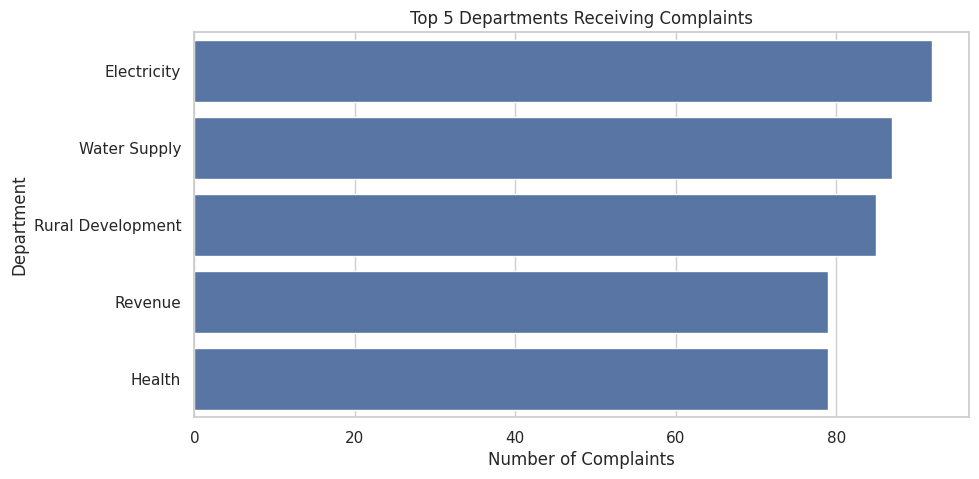

In [8]:
# Visualization 1: Top five departments
department_count = (
    df["Department"]
    .value_counts()
    .head(5)
)

plt.figure(figsize=(10, 5))

sns.barplot(
    x=department_count.values,
    y=department_count.index
)

plt.title("Top 5 Departments Receiving Complaints")

plt.xlabel("Number of Complaints")

plt.ylabel("Department")

plt.show()

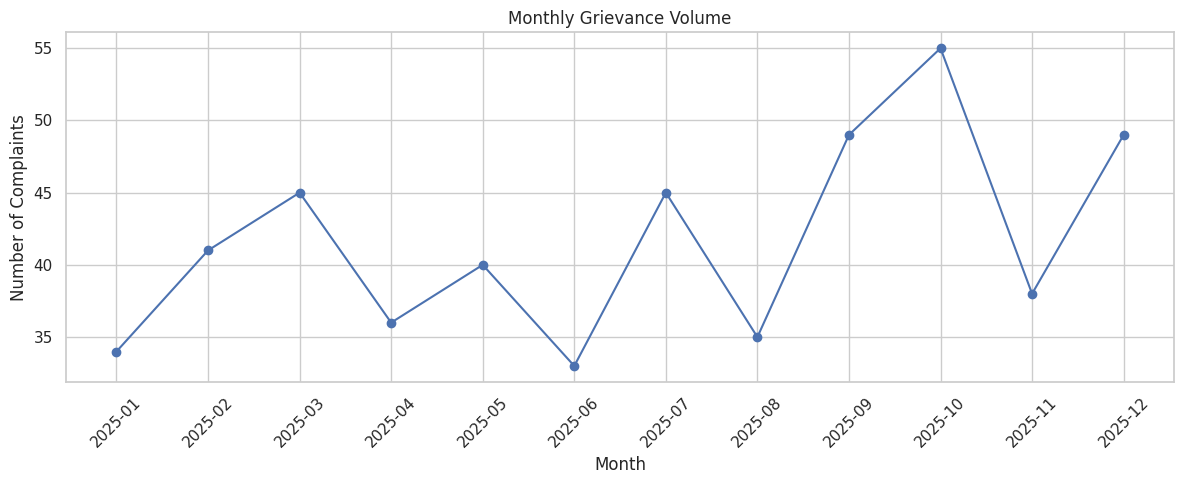

In [9]:
# Visualization 2: Monthly complaint trends
df["Date"] = pd.to_datetime(df["Date"])

monthly_complaints = (
    df.groupby(df["Date"].dt.to_period("M"))
    .size()
)

monthly_complaints.index = (
    monthly_complaints.index.astype(str)
)

plt.figure(figsize=(12, 5))

plt.plot(
    monthly_complaints.index,
    monthly_complaints.values,
    marker="o"
)

plt.title("Monthly Grievance Volume")

plt.xlabel("Month")

plt.ylabel("Number of Complaints")

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()

In [10]:
# Predictive Machine Learning
# Prepare training and testing datasets
X = df["Clean_Description"]

y = df["Department"]

X_train, X_test, y_train, y_test = train_test_split(

    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y

)

print("Training records:", len(X_train))

print("Testing records:", len(X_test))

Training records: 400
Testing records: 100


In [11]:
# Train the ML model
model = Pipeline([

    ("tfidf", TfidfVectorizer(
        ngram_range=(1, 2),
        max_features=5000
    )),

    ("classifier", LogisticRegression(
        max_iter=1000
    ))

])

model.fit(X_train, y_train)

print("Machine Learning Model Trained Successfully")

Machine Learning Model Trained Successfully


In [12]:
# Evaluate model performance
y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

print("\nClassification Report:")

print(classification_report(y_test, y_pred))

Model Accuracy: 100.0 %

Classification Report:
                   precision    recall  f1-score   support

        Education       1.00      1.00      1.00        16
      Electricity       1.00      1.00      1.00        18
           Health       1.00      1.00      1.00        16
          Revenue       1.00      1.00      1.00        16
Rural Development       1.00      1.00      1.00        17
     Water Supply       1.00      1.00      1.00        17

         accuracy                           1.00       100
        macro avg       1.00      1.00      1.00       100
     weighted avg       1.00      1.00      1.00       100



<Figure size 900x700 with 0 Axes>

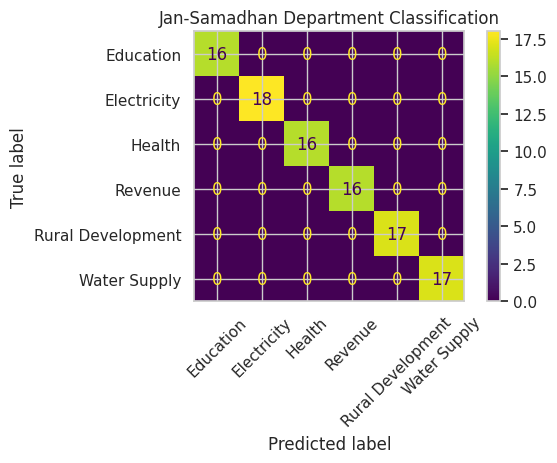

In [13]:
# Confusion matrix
plt.figure(figsize=(9, 7))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    xticks_rotation=45
)

plt.title("Jan-Samadhan Department Classification")

plt.tight_layout()

plt.show()

In [14]:
# Predict a new citizen complaint
new_complaint = """
My pension payment has not been credited
to my bank account for three months.
Please take necessary action.
"""

cleaned = clean_text(new_complaint)

prediction = model.predict([cleaned])

probability = model.predict_proba([cleaned]).max()

print("Citizen Complaint:")
print(new_complaint)

print("Predicted Department:", prediction[0])

print("Prediction Confidence:", round(probability * 100, 2), "%")

Citizen Complaint:

My pension payment has not been credited
to my bank account for three months.
Please take necessary action.

Predicted Department: Rural Development
Prediction Confidence: 71.9 %


In [15]:
# Mini-RAG simulation
sop_documents = [

    """
    Acknowledgment:
    Every grievance received through the portal
    should be acknowledged in the system.
    Include the grievance reference number when available.
    """,

    """
    Initial Examination:
    The receiving office should examine the subject
    and identify the department competent to handle the matter.
    """,

    """
    Urgent Grievances:
    Complaints involving immediate threats to life,
    public safety or essential services should be
    flagged for prompt human review.
    """,

    """
    Privacy:
    Aadhaar numbers, bank account details, mobile
    numbers and addresses must be protected.
    Access should be restricted to authorized personnel.
    """
]

In [16]:
# Create the retrieval system
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

vectorizer = TfidfVectorizer(stop_words="english")

sop_vectors = vectorizer.fit_transform(sop_documents)


def retrieve_sop(query):

    query_vector = vectorizer.transform([query])

    similarity = cosine_similarity(
        query_vector,
        sop_vectors
    )

    best_index = similarity.argmax()

    return sop_documents[best_index]


citizen_query = """
How should the department acknowledge a grievance
and handle urgent complaints?
"""

result = retrieve_sop(citizen_query)

print("Retrieved SOP Information:")
print(result)

Retrieved SOP Information:

    Initial Examination:
    The receiving office should examine the subject
    and identify the department competent to handle the matter.
    


In [20]:
# create a simple grounded answer
def generate_rag_response(query):

    context = retrieve_sop(query)

    response = f"""
    Citizen Query:
    {query}

    Retrieved Government SOP:
    {context}

    Answer:
    Based only on the provided SOP, the concerned
    office should follow the procedures described
    in the retrieved guideline. Any matter involving
    immediate safety concerns should be referred
    for prompt human review.
    """

    return response


print(generate_rag_response(citizen_query))


    Citizen Query:
    
How should the department acknowledge a grievance
and handle urgent complaints?


    Retrieved Government SOP:
    
    Initial Examination:
    The receiving office should examine the subject
    and identify the department competent to handle the matter.
    

    Answer:
    Based only on the provided SOP, the concerned
    office should follow the procedures described
    in the retrieved guideline. Any matter involving
    immediate safety concerns should be referred
    for prompt human review.
    


In [21]:
# Phase 4 – Governance, Ethics and Security
#  PII masking using Python Regex
def mask_pii(text):

    # Mask Aadhaar-like 12 digit number
    text = re.sub(
        r'\b\d{4}[ -]?\d{4}[ -]?\d{4}\b',
        '[AADHAAR MASKED]',
        text
    )

    # Mask Indian mobile number
    text = re.sub(
        r'(?<!\d)(?:\+91[- ]?|0)?[6-9]\d{9}(?!\d)',
        '[MOBILE MASKED]',
        text
    )

    # Mask email address
    text = re.sub(
        r'\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b',
        '[EMAIL MASKED]',
        text
    )

    return text


sample_text = """
My Aadhaar number is 123456789012.
My mobile number is 9876543210.
My email is citizen@gmail.com.
"""

print("Original Text:")
print(sample_text)

print("\nMasked Text:")
print(mask_pii(sample_text))

Original Text:

My Aadhaar number is 123456789012.
My mobile number is 9876543210.
My email is citizen@gmail.com.


Masked Text:

My Aadhaar number is [AADHAAR MASKED].
My mobile number is [MOBILE MASKED].
My email is [EMAIL MASKED].

